# Regresja

In [47]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
sns.set_theme()

Weryfikacja wersji pakietow

In [48]:
print("numpy:", np.__version__)
print("pandas:", pd.__version__)
print("matplotlib:", matplotlib.__version__)
print("seaborn:", sns.__version__)
print("sklearn:", sklearn.__version__)

numpy: 2.2.6
pandas: 2.3.3
matplotlib: 3.11.2
seaborn: 0.13.2
sklearn: 1.7.2


Wczytanie danych

In [49]:
dane = pd.read_csv("reglin_1.csv")
x = dane["x"].to_numpy()
y = dane["y"].to_numpy()
dane.head()

,x,y
0,3.745401,3.229269
1,9.507143,14.185654
2,7.319939,9.524231
3,5.986585,6.672066
4,1.560186,-3.358149


Wyliczenie a i b metoda najmniejszych kwadratow

In [50]:
x_sr = x.mean()
y_sr = y.mean()

a = np.sum((x - x_sr) * (y - y_sr)) / np.sum((x - x_sr) ** 2)
b = y_sr - a * x_sr

print("a =", a)
print("b =", b)

a = 1.9776566003853109
b = -4.903310725531116


Wykres danych i prostej regresji

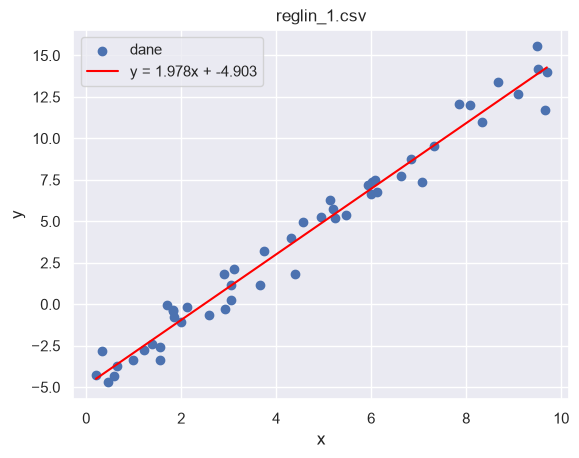

In [51]:
x_linia = np.linspace(x.min(), x.max(), 100)

plt.scatter(x, y, label="dane")
plt.plot(x_linia, a * x_linia + b, color="red", label=f"y = {a:.3f}x + {b:.3f}")
plt.title("reglin_1.csv")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

Metryki modelu

In [52]:
y_pred = a * x + b

mae = np.mean(np.abs(y - y_pred))
mse = np.mean((y - y_pred) ** 2)
rmse = np.sqrt(mse)

print("MAE  =", mae)
print("MSE  =", mse)
print("RMSE =", rmse)

MAE  = 0.7306407201834605
MSE  = 0.8230711437486876
RMSE = 0.9072326844579001


Powtorzenie dla zbiorow reglin_2.csv i reglin_3.csv

In [53]:
def regresja(x, y):
    x_sr = x.mean()
    y_sr = y.mean()
    a = np.sum((x - x_sr) * (y - y_sr)) / np.sum((x - x_sr) ** 2)
    b = y_sr - a * x_sr
    return a, b


def metryki(y, y_pred):
    mae = np.mean(np.abs(y - y_pred))
    mse = np.mean((y - y_pred) ** 2)
    return mae, mse, np.sqrt(mse)

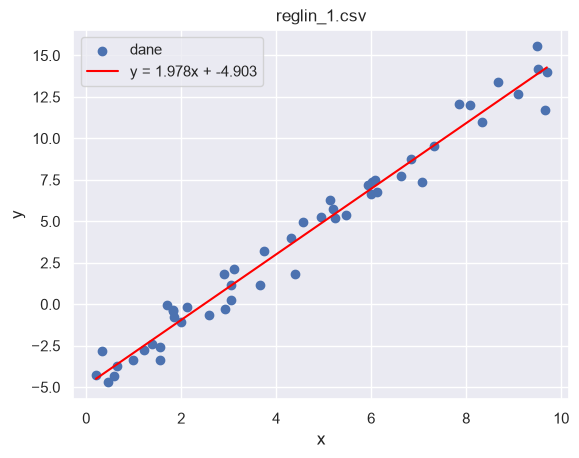

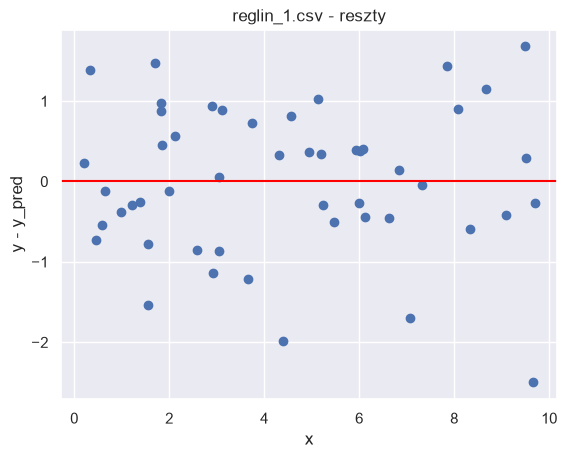

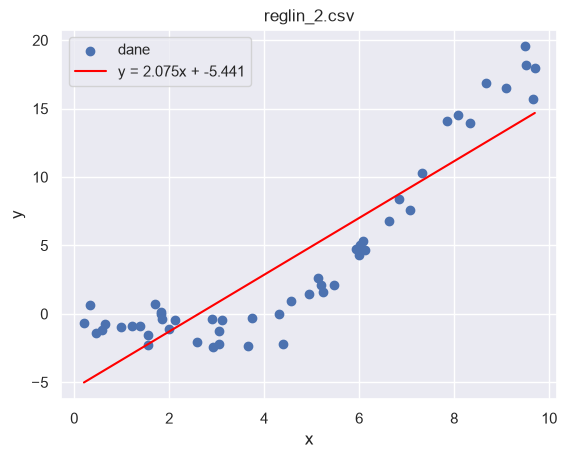

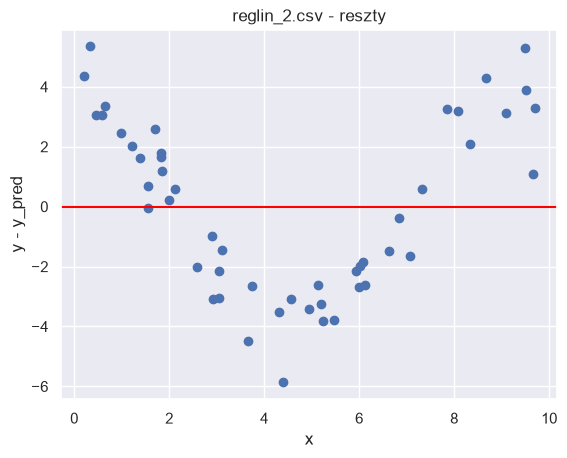

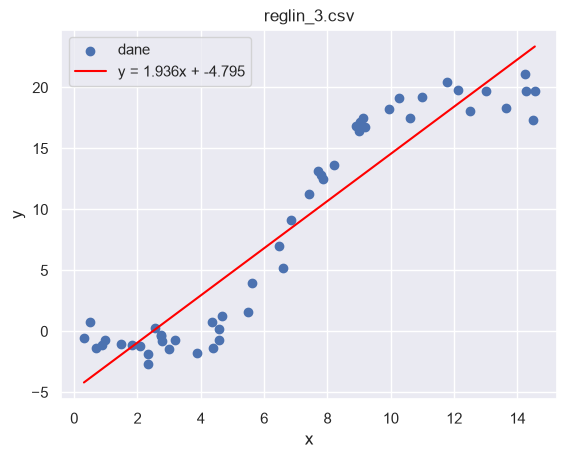

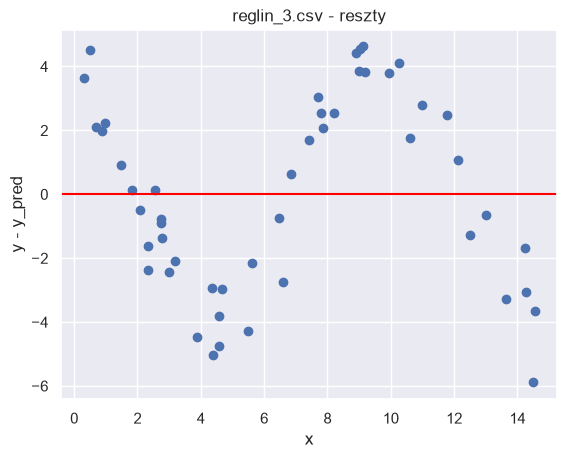

In [54]:
pliki = ["reglin_1.csv", "reglin_2.csv", "reglin_3.csv"]
wyniki = []

for plik in pliki:
    dane = pd.read_csv(plik)
    x = dane["x"].to_numpy()
    y = dane["y"].to_numpy()

    a, b = regresja(x, y)
    y_pred = a * x + b
    mae, mse, rmse = metryki(y, y_pred)
    wyniki.append({"plik": plik, "a": a, "b": b, "MAE": mae, "MSE": mse, "RMSE": rmse})

    x_linia = np.linspace(x.min(), x.max(), 100)

    plt.scatter(x, y, label="dane")
    plt.plot(x_linia, a * x_linia + b, color="red", label=f"y = {a:.3f}x + {b:.3f}")
    plt.title(plik)
    plt.xlabel("x")
    plt.ylabel("y")
    plt.legend()
    plt.show()

    plt.scatter(x, y - y_pred)
    plt.axhline(0, color="red")
    plt.title(f"{plik} - reszty")
    plt.xlabel("x")
    plt.ylabel("y - y_pred")
    plt.show()

In [55]:
pd.DataFrame(wyniki).set_index("plik").round(4)

,a,b,MAE,MSE,RMSE
plik,,,,,
reglin_1.csv,1.9777,-4.9033,0.7306,0.8231,0.9072
reglin_2.csv,2.0749,-5.4405,2.5635,8.3448,2.8887
reglin_3.csv,1.9355,-4.7953,2.6176,8.8797,2.9799


Komentarz

reglin_1 - dane sa liniowe, prosta dobrze pasuje, bledy male (RMSE ok. 0.9).

reglin_2 - dane ukladaja sie w krzywa (parabole), prosta do nich nie pasuje, bledy ok. 3 razy wieksze (RMSE ok. 2.9).

reglin_3 - trend rosnie, ale dane sa "falowane", prosta tego nie lapie, bledy podobne jak w 2 (RMSE ok. 3).

a i b wyszly podobne we wszystkich zbiorach, wiec same nie mowia czy model jest dobry. Metryki pokazuja jak duzy jest blad, a wykres czy prosta w ogole pasuje do danych - model jest dobry tylko w reglin_1.

In [56]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

lr = LinearRegression()
df = pd.read_csv("reglin_1.csv")
lr.fit(df[["x"]], df["y"])
yp=lr.predict(df[["x"]])

In [57]:
print("a =", lr.coef_[0])
print("b =", lr.intercept_)

a = 1.9776566003853107
b = -4.903310725531115


In [58]:
mae = mean_absolute_error(df["y"], yp)
mse = mean_squared_error(df["y"], yp)
rmse = np.sqrt(mse)

print("MAE  =", mae)
print("MSE  =", mse)
print("RMSE =", rmse)

MAE  = 0.7306407201834605
MSE  = 0.8230711437486881
RMSE = 0.9072326844579003


Regresja dla reglin_12 (dwie zmienne x1 i x2)

In [59]:
df12 = pd.read_csv("reglin_12.csv")

lr12 = LinearRegression()
lr12.fit(df12[["x1", "x2"]], df12["y"])
yp12 = lr12.predict(df12[["x1", "x2"]])

print("a1 =", lr12.coef_[0])
print("a2 =", lr12.coef_[1])
print("b  =", lr12.intercept_)

a1 = 1.8729619193032725
a2 = -3.0004508731232846
b  = 5.586753915354075


In [60]:
mae = mean_absolute_error(df12["y"], yp12)
mse = mean_squared_error(df12["y"], yp12)
rmse = np.sqrt(mse)

print("MAE  =", mae)
print("MSE  =", mse)
print("RMSE =", rmse)

MAE  = 0.7070638224462258
MSE  = 0.775806368834028
RMSE = 0.8807987107359024


In [61]:
x1_fit=np.linspace(0,10,100)
x2_fit=np.linspace(0,7,100)
x1,x2=np.meshgrid(x1_fit,x2_fit)
y=lr12.coef_[0]*x1+lr12.coef_[1]*x2+lr12.intercept_

rysunki:

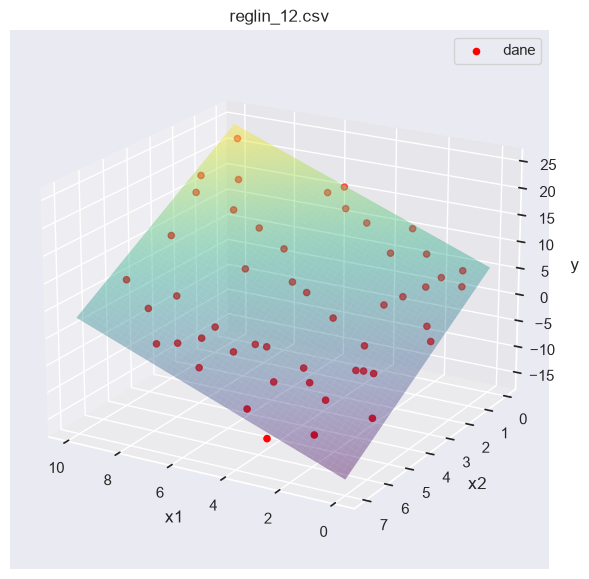

In [62]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(x1, x2, y, alpha=0.4, cmap="viridis", edgecolor="none")
ax.scatter(df12["x1"], df12["x2"], df12["y"], color="red", label="dane")
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_zlabel("y")
ax.set_title("reglin_12.csv")
ax.view_init(elev=20, azim=120)
ax.legend()
plt.show()